In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
# 
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import classification_report, f1_score
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
# Cell 2: Load dataset & basic inspection
train_df = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("Train Data Preview:")
display(train_df.head())

Train shape: (198000, 15)
Test shape: (102000, 14)
Train Data Preview:


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


In [4]:
print("\n🔹 Data Types & Non-null Info:")
train_df.info()


🔹 Data Types & Non-null Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


In [5]:
print("\n🔹 Missing Values (Top 20):")
print(train_df.isnull().sum().sort_values(ascending=False))


🔹 Missing Values (Top 20):
gender          145423
race            145423
religion        145423
comment              1
created_date         0
post_id              0
emoticon_1           0
downvote             0
upvote               0
emoticon_3           0
emoticon_2           0
if_1                 0
if_2                 0
disability           0
label                0
dtype: int64


In [6]:
# Cell 3: Target variable distribution

print("Label value counts:")
display(train_df['label'].value_counts())

print("\nLabel percentage distribution:")
display(train_df['label'].value_counts(normalize=True) * 100)

Label value counts:


label
0    114173
2     62440
1     15918
3      5469
Name: count, dtype: int64


Label percentage distribution:


label
0    57.663131
2    31.535354
1     8.039394
3     2.762121
Name: proportion, dtype: float64

**Visualization--->**

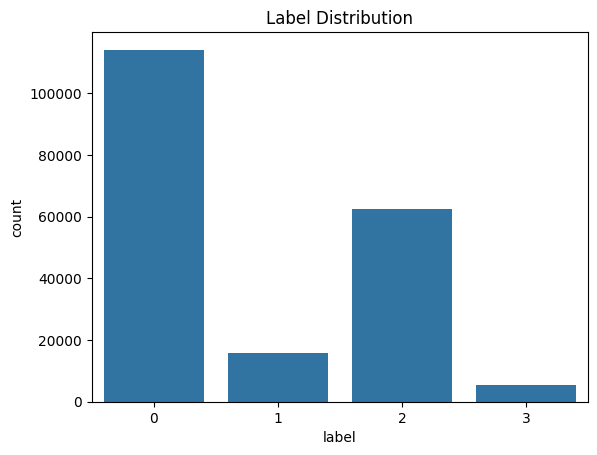

In [7]:
sns.countplot(x='label', data=train_df)
plt.title("Label Distribution")
plt.show()

###  Observation:
The count plot shows the distribution of different categories in the dataset.  
It is observed that **label 0 has the highest number of samples**, followed by label 2.  
Labels 1 and 3 have significantly fewer samples.
###  Insight:
This indicates that the dataset is **imbalanced**, where some classes have more data than others.  
Such imbalance can affect model performance, as the model may become biased towards majority classes.
###  Action Taken:
To handle this issue, i used techniques like **class_weight='balanced'** in models, which helps give equal importance to all classes during training.
###  Conclusion:
Understanding label distribution is important to ensure fair and accurate predictions across all categories.

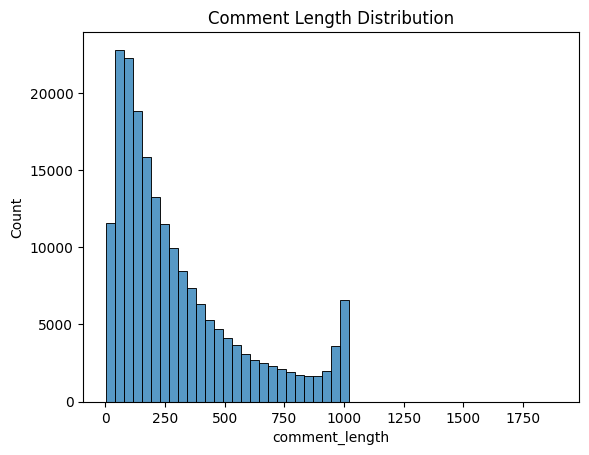

In [8]:
# train_df['comment_length'] = train_df['comment'].apply(len)
train_df['comment_length'] = train_df['comment'].astype(str).apply(len)
sns.histplot(train_df['comment_length'], bins=50)
plt.title("Comment Length Distribution")
plt.show()

###  Observation:
The histogram shows the distribution of comment lengths in the dataset.  
Most comments are concentrated in the **lower length range (short comments)**, while very long comments are relatively rare.
###  Insight:
This indicates that users generally write **short to medium-length comments**.  
A few long comments exist, which may act as **outliers**.
###  Importance:
Comment length can be an important feature, as:
- Short comments may contain less information  
- Longer comments may provide more context and detailed expressions  
###  Conclusion:
The dataset is dominated by short comments, which may influence how the model learns textual patterns.

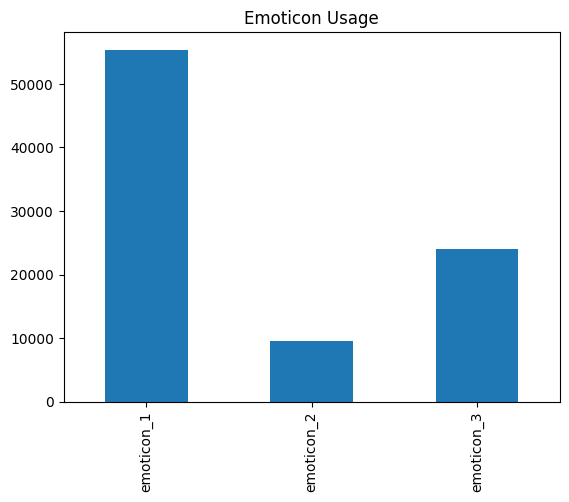

In [9]:
cols = ['emoticon_1', 'emoticon_2', 'emoticon_3']
train_df[cols].sum().plot(kind='bar')
plt.title("Emoticon Usage")
plt.show()

### Observation:
The bar chart shows the usage frequency of different emoticon groups.  
It is observed that **emoticon_1 is used the most**, followed by emoticon_3, while emoticon_2 is used the least.
### Insight:
This indicates that certain types of emoticons are more commonly used by users.  
Emoticons can represent **emotions, tone, or intent** of a comment.
### Importance:
Emoticons act as **strong indicators of sentiment**, such as:
- Positive emotion  
- Negative emotion  
- Sarcasm or expression  
These features can significantly help the model in better classification.
### Conclusion:
Emoticon features provide valuable emotional context and can improve model performance when combined with text data.

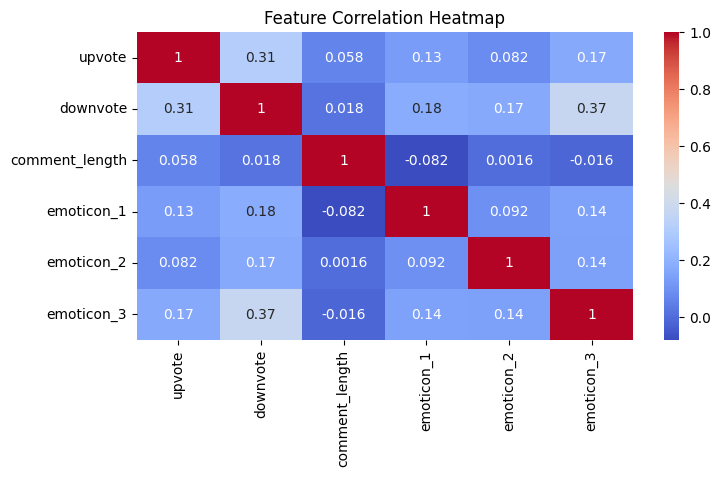

In [10]:
# Only numeric columns
num_cols = ['upvote', 'downvote', 'comment_length', 
            'emoticon_1', 'emoticon_2', 'emoticon_3']

corr = train_df[num_cols].corr()

plt.figure(figsize=(8,4))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

### Observation:
Most features show low correlation with each other.  
Upvotes and downvotes have a moderate positive correlation.
### Insight:
Low correlation means features provide independent information.
### Conclusion:
Low multicollinearity is good and helps improve model performance.

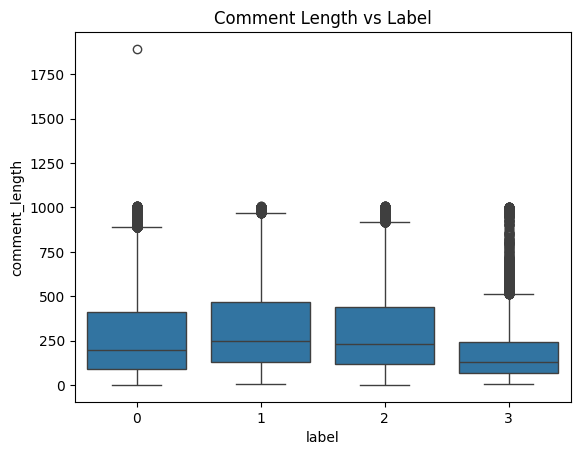

In [11]:
sns.boxplot(x='label', y='comment_length', data=train_df)
plt.title("Comment Length vs Label")
plt.show()

## Comment Length vs Label Analysis

### Observation:
The boxplot shows the distribution of comment length across different categories (labels).  
It is observed that each label has a different spread of comment lengths, with some variations in median and range.

### Insight:
- Some categories tend to have **longer comments**, while others have shorter ones.  
- There are also **outliers**, indicating very long comments in certain categories.

### Importance:
This suggests that **comment length is an informative feature** and may help the model distinguish between different categories.

### Conclusion:
Comment length varies across labels, making it a useful feature for classification.

**PreProcessing--->**

In [12]:
df_train=train_df.copy()
df_test=test_df.copy()

In [13]:
#Basic cleaning
for col in ['race', 'religion', 'gender']:
    df_train[col] = df_train[col].fillna('Unknown')
    df_test[col] = df_test[col].fillna('Unknown')

df_train['comment'] = df_train['comment'].fillna('')
df_test['comment'] = df_test['comment'].fillna('')

In [14]:
df_train['comment_length'] = df_train['comment'].astype(str).apply(len)
df_test['comment_length'] = df_test['comment'].astype(str).apply(len)

numeric_cols = [
    'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
    'upvote', 'downvote', 'if_1', 'if_2', 'comment_length'
]
bool_cols = ['disability']
cat_cols = ['race', 'religion', 'gender']
text_col = 'comment'

In [15]:
#Text pipeline
text_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        stop_words='english',
        min_df=5,
        sublinear_tf=True
    ))
])
#categorical pipeline
cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

num_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('text', text_pipeline, text_col),
    ('cat', cat_pipeline, cat_cols),
    ('num', num_pipeline, numeric_cols + bool_cols)
])

X_all_train = preprocessor.fit_transform(df_train)
X_all_test = preprocessor.transform(df_test)

y = df_train['label']

In [16]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_all_train,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train shape:", X_train.shape)
print("Valid shape:", X_valid.shape)

Train shape: (158400, 30032)
Valid shape: (39600, 30032)


**Model_Building--->**

In [17]:
# Cell 9: Baseline Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

lr = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    n_jobs=-1
)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_valid)

print("Logistic Regression Results:")
print(classification_report(y_valid, y_pred_lr))

f1_macro_lr = f1_score(y_valid, y_pred_lr, average='macro')
print("Macro F1:", f1_macro_lr)

Logistic Regression Results:
              precision    recall  f1-score   support

           0       0.98      0.93      0.96     22835
           1       0.68      0.85      0.75      3183
           2       0.88      0.86      0.87     12488
           3       0.48      0.76      0.59      1094

    accuracy                           0.90     39600
   macro avg       0.76      0.85      0.79     39600
weighted avg       0.91      0.90      0.90     39600

Macro F1: 0.7925729005844578


In [18]:
# Cell X: Hyperparameter Tuning (Logistic Regression)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],          # regularization strength
    'solver': ['lbfgs'],        # safe solver
    'penalty': ['l2']           # compatible with lbfgs
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight='balanced'),
    param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)
grid_lr.fit(X_train, y_train)

print("Best Parameters:", grid_lr.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


In [19]:
# Use best model
lr_hpt = grid_lr.best_estimator_

y_pred_lr_hpt = lr_hpt.predict(X_valid)

from sklearn.metrics import classification_report, f1_score

print("Tuned Logistic Regression Results:")
print(classification_report(y_valid, y_pred_lr_hpt))

f1_macro_tunedlr = f1_score(y_valid, y_pred_lr_hpt, average='macro')
print("Macro F1:", f1_macro_tunedlr)

Tuned Logistic Regression Results:
              precision    recall  f1-score   support

           0       0.98      0.93      0.96     22835
           1       0.68      0.85      0.75      3183
           2       0.88      0.86      0.87     12488
           3       0.48      0.76      0.59      1094

    accuracy                           0.90     39600
   macro avg       0.75      0.85      0.79     39600
weighted avg       0.91      0.90      0.90     39600

Macro F1: 0.7920759599014549


In [20]:
# Cell 10: XGBoost Model

import xgboost as xgb
from sklearn.metrics import classification_report, f1_score

xgb_model = xgb.XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_valid)

print("XGBoost Results:")
print(classification_report(y_valid, y_pred_xgb))

f1_macro_xgb = f1_score(y_valid, y_pred_xgb, average='macro')
print("Macro F1 (XGBoost):", f1_macro_xgb)

XGBoost Results:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96     22835
           1       0.77      0.76      0.77      3183
           2       0.84      0.92      0.88     12488
           3       0.75      0.42      0.54      1094

    accuracy                           0.91     39600
   macro avg       0.83      0.76      0.79     39600
weighted avg       0.91      0.91      0.91     39600

Macro F1 (XGBoost): 0.7854960951316089


In [21]:
# from xgboost import XGBClassifier
# from sklearn.model_selection import GridSearchCV

# xgb = XGBClassifier(
#     eval_metric='mlogloss',
#     use_label_encoder=False
# )

# param_grid = {
#     'n_estimators': [100, 200],
#     'max_depth': [4, 6],
#     'learning_rate': [0.05, 0.1]
# }
# grid_xgb = GridSearchCV(
#     xgb,
#     param_grid,
#     cv=3,
#     scoring='f1_macro',
#     n_jobs=-1,
#     verbose=1
# )
# grid_xgb.fit(X_train, y_train)

# print("Best Params:", grid_xgb.best_params_)

# # IMPORTANT (same variable name)
# xgb = grid_xgb.best_estimator_

In [22]:
# # Use best model
# xgb_model = xgb

# y_pred_xgb = xgb_model.predict(X_valid)

# from sklearn.metrics import classification_report, f1_score

# print("Tuned Xgboost Regression Results:")
# print(classification_report(y_valid, y_pred_xgb))

# f1_macro = f1_score(y_valid, y_pred_lr, average='macro')
# print("Macro F1:", f1_macro)

In [23]:
# Cell: Model 3 – Linear SVM
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score

svm_model = LinearSVC(
    class_weight='balanced',
    max_iter=5000
)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_valid)

print("Linear SVM Results:")
print(classification_report(y_valid, y_pred_svm))

svm_f1 = f1_score(y_valid, y_pred_svm, average='macro')
print("Macro F1 (SVM):", svm_f1)

Linear SVM Results:
              precision    recall  f1-score   support

           0       0.84      0.85      0.85     22835
           1       0.62      0.72      0.67      3183
           2       0.78      0.72      0.75     12488
           3       0.44      0.54      0.48      1094

    accuracy                           0.79     39600
   macro avg       0.67      0.71      0.69     39600
weighted avg       0.79      0.79      0.79     39600

Macro F1 (SVM): 0.6871552550871998


In [24]:
# Convert SVM decision scores to probabilities

import numpy as np
from scipy.special import softmax

svm_scores = svm_model.decision_function(X_valid)

svm_probs = softmax(svm_scores, axis=1)

In [25]:
#{{ MODEL 4 }}----------->

# from sklearn.naive_bayes import MultinomialNB
# from sklearn.metrics import classification_report, f1_score

# nb_model = MultinomialNB()

# nb_model.fit(X_train, y_train)

# y_pred_nb = nb_model.predict(X_valid)

# print("Naive Bayes Results:")
# print(classification_report(y_valid, y_pred_nb))

# nb_f1 = f1_score(y_valid, y_pred_nb, average='macro')
# print("Macro F1 (Naive Bayes):", nb_f1)

In [26]:
# 3 Model Ensemble

lr_probs = lr.predict_proba(X_valid)
xgb_probs = xgb_model.predict_proba(X_valid)
# nb_probs = nb_model.predict_proba(X_valid)

ensemble_probs = (lr_probs + xgb_probs + svm_probs) / 3

y_pred_ensemble = ensemble_probs.argmax(axis=1)

print("3 Model Ensemble Results:")
print(classification_report(y_valid, y_pred_ensemble))

f1_macro_ensemble = f1_score(y_valid, y_pred_ensemble, average='macro')
print("Macro F1 (3 Model Ensemble):", f1_macro_ensemble)

3 Model Ensemble Results:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96     22835
           1       0.74      0.82      0.77      3183
           2       0.87      0.91      0.89     12488
           3       0.65      0.65      0.65      1094

    accuracy                           0.91     39600
   macro avg       0.81      0.83      0.82     39600
weighted avg       0.92      0.91      0.91     39600

Macro F1 (3 Model Ensemble): 0.8190384669448327


In [27]:
# SVM predictions for test data

svm_scores_test = svm_model.decision_function(X_all_test)

svm_probs_test = softmax(svm_scores_test, axis=1)

# Logistic + XGB + SVM

lr_test_probs = lr.predict_proba(X_all_test)
xgb_test_probs = xgb_model.predict_proba(X_all_test)

final_probs = (lr_test_probs + xgb_test_probs + svm_probs_test) / 3

test_predictions = final_probs.argmax(axis=1)

In [28]:
submission = pd.DataFrame({
    "ID": df_test.index + 1,
    "label": test_predictions
})
submission.to_csv("submission.csv", index=False)
print("submission.csv generated")
submission.head()

submission.csv generated


,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2


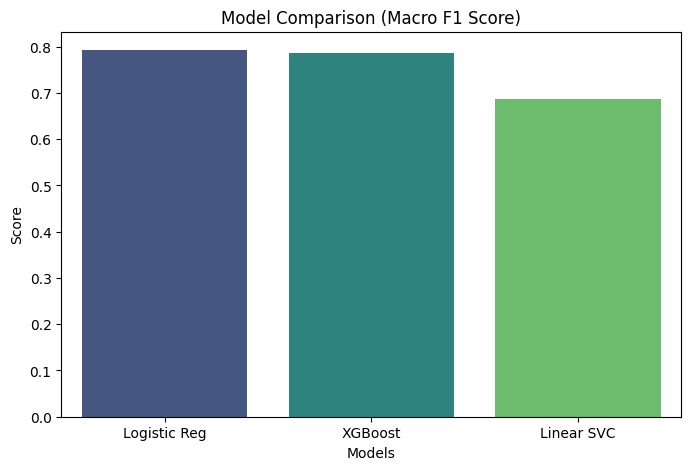

In [29]:
#Model Comparison
model_names = ['Logistic Reg', 'XGBoost', 'Linear SVC']
scores = [f1_macro_lr, f1_macro_xgb, svm_f1]
plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=scores, palette='viridis')

plt.title('Model Comparison (Macro F1 Score)')
plt.ylabel('Score')
plt.xlabel('Models')
plt.show()